<a href="https://colab.research.google.com/github/Cloud-Architect-Emma/minillm-research-lab/blob/main/05_attention_optimisation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import sys
import json
import time
import math
import random
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

SEED = 42

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU capability:",
        torch.cuda.get_device_capability(0)
    )

print("SDPA available:", hasattr(F, "scaled_dot_product_attention"))

assert hasattr(F, "scaled_dot_product_attention")

print("PASS: Research environment ready")


Python: 3.13.16
PyTorch: 2.14.1+cu130
Device: cuda
GPU: Tesla T4
GPU capability: (7, 5)
SDPA available: True
PASS: Research environment ready


In [2]:

ROOT = Path("minillm_lab5")
RESULTS_DIR = ROOT / "results"
FIGURES_DIR = RESULTS_DIR / "figures"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Results directory:", RESULTS_DIR)
print("Figures directory:", FIGURES_DIR)


Results directory: minillm_lab5/results
Figures directory: minillm_lab5/results/figures


In [3]:

def manual_attention(q, k, v):
    head_dim = q.size(-1)

    scores = (
        q @ k.transpose(-2, -1)
    ) * (head_dim ** -0.5)

    sequence_length = q.size(-2)

    causal_mask = torch.ones(
        sequence_length,
        sequence_length,
        device=q.device,
        dtype=torch.bool
    ).tril()

    scores = scores.masked_fill(
        ~causal_mask,
        float("-inf")
    )

    weights = F.softmax(
        scores,
        dim=-1
    )

    return weights @ v


print("Manual attention implemented")


Manual attention implemented


In [4]:

def sdpa_attention(q, k, v):
    return F.scaled_dot_product_attention(
        q,
        k,
        v,
        attn_mask=None,
        dropout_p=0.0,
        is_causal=True
    )


print("PyTorch SDPA implemented")


PyTorch SDPA implemented


In [5]:

batch_size = 4
num_heads = 4
sequence_length = 128
head_dimension = 32

q = torch.randn(
    batch_size,
    num_heads,
    sequence_length,
    head_dimension,
    device=device,
    dtype=torch.float32
)

k = torch.randn_like(q)
v = torch.randn_like(q)

print("Query shape:", q.shape)
print("Key shape:", k.shape)
print("Value shape:", v.shape)

assert q.shape == (
    batch_size,
    num_heads,
    sequence_length,
    head_dimension
)

print("PASS: Attention inputs prepared")


Query shape: torch.Size([4, 4, 128, 32])
Key shape: torch.Size([4, 4, 128, 32])
Value shape: torch.Size([4, 4, 128, 32])
PASS: Attention inputs prepared


In [6]:

with torch.no_grad():
    manual_output = manual_attention(q, k, v)
    sdpa_output = sdpa_attention(q, k, v)

max_difference = (
    manual_output - sdpa_output
).abs().max().item()

print("Manual output shape:", manual_output.shape)
print("SDPA output shape:", sdpa_output.shape)
print("Maximum absolute difference:", max_difference)

assert manual_output.shape == sdpa_output.shape

torch.testing.assert_close(
    manual_output,
    sdpa_output,
    rtol=1e-4,
    atol=1e-5
)

print("PASS: Forward outputs are numerically close")


Manual output shape: torch.Size([4, 4, 128, 32])
SDPA output shape: torch.Size([4, 4, 128, 32])
Maximum absolute difference: 7.152557373046875e-07
PASS: Forward outputs are numerically close


In [7]:

q1 = q.detach().clone().requires_grad_(True)
k1 = k.detach().clone().requires_grad_(True)
v1 = v.detach().clone().requires_grad_(True)

q2 = q.detach().clone().requires_grad_(True)
k2 = k.detach().clone().requires_grad_(True)
v2 = v.detach().clone().requires_grad_(True)

out1 = manual_attention(q1, k1, v1)
out2 = sdpa_attention(q2, k2, v2)

# Same upstream gradient for both implementations
upstream = torch.randn_like(out1)

out1.backward(upstream)
out2.backward(upstream)

for name, grad1, grad2 in [
    ("Query", q1.grad, q2.grad),
    ("Key", k1.grad, k2.grad),
    ("Value", v1.grad, v2.grad)
]:
    max_diff = (grad1 - grad2).abs().max().item()

    print(name, "max gradient difference:", max_diff)

    torch.testing.assert_close(
        grad1,
        grad2,
        rtol=1e-4,
        atol=1e-5
    )

print("PASS: Backward gradients are numerically close")


Query max gradient difference: 7.152557373046875e-07
Key max gradient difference: 1.3113021850585938e-06
Value max gradient difference: 1.6689300537109375e-06
PASS: Backward gradients are numerically close


/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:1072: UserWarning: Attempting to run cuBLAS, but there was no current CUDA context! Attempting to set the primary context... (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/cuda/CublasHandlePool.cpp:410.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


In [9]:

q_test = q.detach().clone()
k_test = k.detach().clone()
v_test = v.detach().clone()

with torch.no_grad():
    original = sdpa_attention(
        q_test, k_test, v_test
    )

    k_test[:, :, -1, :] += 100
    v_test[:, :, -1, :] += 100

    modified = sdpa_attention(
        q_test, k_test, v_test
    )

    earlier_original = original[:, :, :-1, :]
    earlier_modified = modified[:, :, :-1, :]

    torch.testing.assert_close(
        earlier_original,
        earlier_modified,
        rtol=1e-5,
        atol=1e-6
    )

print("PASS: Future tokens cannot influence earlier outputs")


PASS: Future tokens cannot influence earlier outputs


In [10]:

def synchronize():
    if device.type == "cuda":
        torch.cuda.synchronize()


def benchmark_attention(
    attention_fn,
    seq_len,
    training=False,
    repeats=20,
    warmup=5,
    dtype=torch.float32
):
    set_seed(SEED)

    q = torch.randn(
        batch_size,
        num_heads,
        seq_len,
        head_dimension,
        device=device,
        dtype=dtype
    )

    k = torch.randn_like(q)
    v = torch.randn_like(q)

    if training:
        q.requires_grad_(True)
        k.requires_grad_(True)
        v.requires_grad_(True)

    def run_once():
        if training:
            for tensor in (q, k, v):
                tensor.grad = None

            output = attention_fn(q, k, v)
            loss = output.square().mean()
            loss.backward()
        else:
            with torch.no_grad():
                output = attention_fn(q, k, v)

        return output

    # Warm up
    for _ in range(warmup):
        run_once()

    synchronize()

    if device.type == "cuda":
        torch.cuda.reset_peak_memory_stats()

    timings_ms = []

    for _ in range(repeats):
        synchronize()

        start = time.perf_counter()
        run_once()
        synchronize()

        timings_ms.append(
            (time.perf_counter() - start) * 1000
        )

    peak_memory_mb = (
        torch.cuda.max_memory_allocated() / (1024 ** 2)
        if device.type == "cuda"
        else None
    )

    return {
        "median_ms": float(np.median(timings_ms)),
        "mean_ms": float(np.mean(timings_ms)),
        "min_ms": float(np.min(timings_ms)),
        "peak_gpu_memory_mb": peak_memory_mb
    }


print("Benchmark function ready")


Benchmark function ready


In [11]:

pilot_manual = benchmark_attention(
    manual_attention,
    seq_len=128,
    training=False,
    repeats=5,
    warmup=2
)

pilot_sdpa = benchmark_attention(
    sdpa_attention,
    seq_len=128,
    training=False,
    repeats=5,
    warmup=2
)

print("Manual attention:", pilot_manual)
print("SDPA attention:", pilot_sdpa)

print("PASS: Benchmark pilot completed")


Manual attention: {'median_ms': 0.358704999996462, 'mean_ms': 0.3721420000033504, 'min_ms': 0.31630699999141143, 'peak_gpu_memory_mb': 25.515625}
SDPA attention: {'median_ms': 0.11557200002698664, 'mean_ms': 0.11727620000101524, 'min_ms': 0.1111610000066321, 'peak_gpu_memory_mb': 23.5009765625}
PASS: Benchmark pilot completed


In [12]:

sequence_lengths = [32, 128, 256, 512, 1024]

implementations = {
    "Manual": manual_attention,
    "SDPA": sdpa_attention
}

benchmark_rows = []

for seq_len in sequence_lengths:
    for mode in ["inference", "training"]:
        for name, attention_fn in implementations.items():

            print(
                f"Testing {name} | "
                f"Length {seq_len} | {mode}"
            )

            measurement = benchmark_attention(
                attention_fn=attention_fn,
                seq_len=seq_len,
                training=(mode == "training"),
                repeats=20,
                warmup=5
            )

            benchmark_rows.append({
                "implementation": name,
                "sequence_length": seq_len,
                "mode": mode,
                **measurement
            })

            pd.DataFrame(benchmark_rows).to_csv(
                RESULTS_DIR / "attention_benchmarks.csv",
                index=False
            )

results_df = pd.DataFrame(benchmark_rows)

display(results_df)

print("ALL ATTENTION BENCHMARKS COMPLETED")


Testing Manual | Length 32 | inference
Testing SDPA | Length 32 | inference
Testing Manual | Length 32 | training
Testing SDPA | Length 32 | training
Testing Manual | Length 128 | inference
Testing SDPA | Length 128 | inference
Testing Manual | Length 128 | training
Testing SDPA | Length 128 | training
Testing Manual | Length 256 | inference
Testing SDPA | Length 256 | inference
Testing Manual | Length 256 | training
Testing SDPA | Length 256 | training
Testing Manual | Length 512 | inference
Testing SDPA | Length 512 | inference
Testing Manual | Length 512 | training
Testing SDPA | Length 512 | training
Testing Manual | Length 1024 | inference
Testing SDPA | Length 1024 | inference
Testing Manual | Length 1024 | training
Testing SDPA | Length 1024 | training


,implementation,sequence_length,mode,median_ms,mean_ms,min_ms,peak_gpu_memory_mb
0,Manual,32,inference,0.455303,0.461089,0.331820,22.875977
1,SDPA,32,inference,0.074036,0.083632,0.070717,22.750977
2,Manual,32,training,1.366395,1.425061,1.231117,23.064453
3,SDPA,32,training,0.740264,0.755383,0.658957,23.318848
4,Manual,128,inference,0.321085,0.325553,0.292271,25.515625
5,SDPA,128,inference,0.112542,0.117160,0.107023,23.500977
6,Manual,128,training,1.525090,1.687237,1.344706,27.766602
7,SDPA,128,training,0.767662,0.767134,0.684999,25.268066
8,Manual,256,inference,0.452268,0.450803,0.426163,32.562500
9,SDPA,256,inference,0.238891,0.242850,0.231977,24.500977


ALL ATTENTION BENCHMARKS COMPLETED


In [13]:

timing_table = results_df.pivot(
    index=["sequence_length", "mode"],
    columns="implementation",
    values="median_ms"
).reset_index()

timing_table["sdpa_speedup"] = (
    timing_table["Manual"] /
    timing_table["SDPA"]
)

display(timing_table.round(3))

timing_table.to_csv(
    RESULTS_DIR / "speedup_comparison.csv",
    index=False
)


implementation,sequence_length,mode,Manual,SDPA,sdpa_speedup
0,32,inference,0.455,0.074,6.150
1,32,training,1.366,0.740,1.846
2,128,inference,0.321,0.113,2.853
3,128,training,1.525,0.768,1.987
4,256,inference,0.452,0.239,1.893
5,256,training,1.541,1.117,1.379
6,512,inference,1.134,0.504,2.250
7,512,training,2.604,1.759,1.480
8,1024,inference,3.708,1.140,3.253
9,1024,training,8.657,2.913,2.972


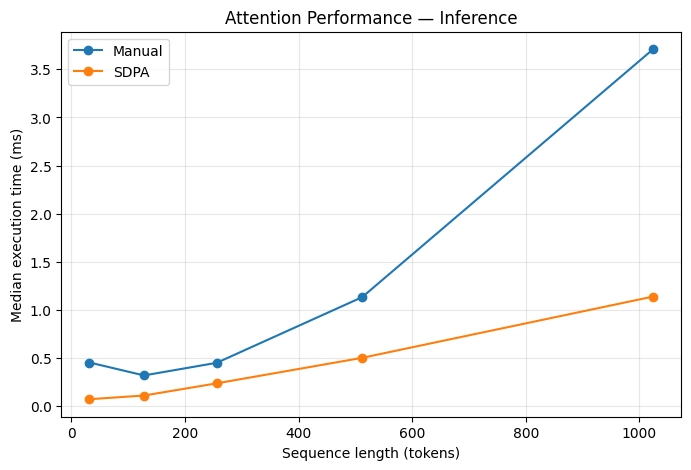

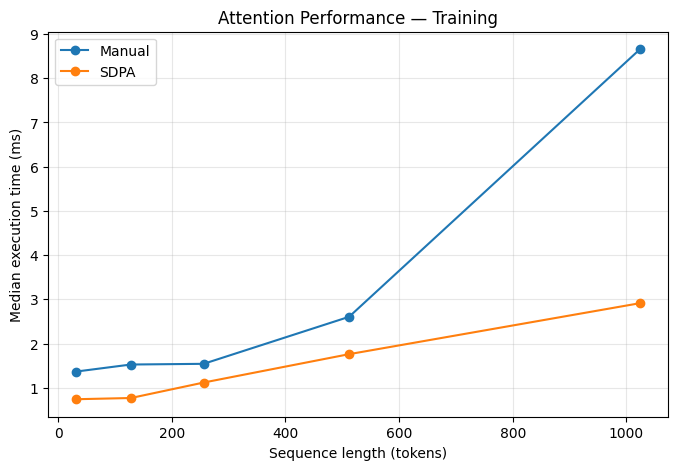

In [14]:

for mode in ["inference", "training"]:
    subset = results_df[
        results_df["mode"] == mode
    ]

    plt.figure(figsize=(8, 5))

    for implementation in ["Manual", "SDPA"]:
        rows = subset[
            subset["implementation"] == implementation
        ].sort_values("sequence_length")

        plt.plot(
            rows["sequence_length"],
            rows["median_ms"],
            marker="o",
            label=implementation
        )

    plt.title(f"Attention Performance — {mode.title()}")
    plt.xlabel("Sequence length (tokens)")
    plt.ylabel("Median execution time (ms)")
    plt.legend()
    plt.grid(True, alpha=0.3)

    plt.savefig(
        FIGURES_DIR / f"{mode}_latency.png",
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()


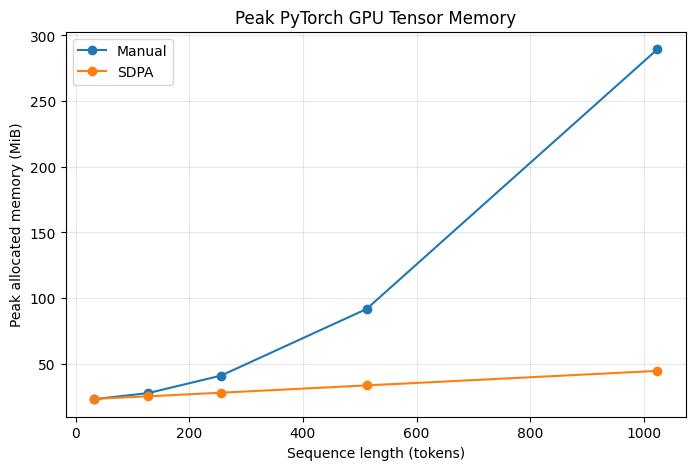

In [15]:

if device.type == "cuda":
    subset = results_df[
        results_df["mode"] == "training"
    ]

    plt.figure(figsize=(8, 5))

    for implementation in ["Manual", "SDPA"]:
        rows = subset[
            subset["implementation"] == implementation
        ].sort_values("sequence_length")

        plt.plot(
            rows["sequence_length"],
            rows["peak_gpu_memory_mb"],
            marker="o",
            label=implementation
        )

    plt.title("Peak PyTorch GPU Tensor Memory")
    plt.xlabel("Sequence length (tokens)")
    plt.ylabel("Peak allocated memory (MiB)")
    plt.legend()
    plt.grid(True, alpha=0.3)

    plt.savefig(
        FIGURES_DIR / "gpu_memory.png",
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()
else:
    print(
        "GPU memory benchmark unavailable: "
        "the experiment is running on CPU."
    )


In [16]:

if device.type == "cuda":
    print(
        "Flash SDPA enabled:",
        torch.backends.cuda.flash_sdp_enabled()
    )
    print(
        "Memory-efficient SDPA enabled:",
        torch.backends.cuda.mem_efficient_sdp_enabled()
    )
    print(
        "Math SDPA enabled:",
        torch.backends.cuda.math_sdp_enabled()
    )
else:
    print("CUDA backend inspection requires a GPU")


Flash SDPA enabled: True
Memory-efficient SDPA enabled: True
Math SDPA enabled: True


In [17]:

if device.type == "cuda":
    fp16_manual = benchmark_attention(
        manual_attention,
        seq_len=512,
        training=False,
        repeats=20,
        dtype=torch.float16
    )

    fp16_sdpa = benchmark_attention(
        sdpa_attention,
        seq_len=512,
        training=False,
        repeats=20,
        dtype=torch.float16
    )

    print("FP16 manual:", fp16_manual)
    print("FP16 SDPA:", fp16_sdpa)

    print(
        "FP16 speedup:",
        round(
            fp16_manual["median_ms"] /
            fp16_sdpa["median_ms"],
            3
        )
    )
else:
    print("Skipping FP16 GPU benchmark")


FP16 manual: {'median_ms': 0.6949305000034656, 'mean_ms': 0.7074166500018464, 'min_ms': 0.6538910000131182, 'peak_gpu_memory_mb': 40.75}
FP16 SDPA: {'median_ms': 0.18055400002481292, 'mean_ms': 0.1973419499989859, 'min_ms': 0.1639129999944089, 'peak_gpu_memory_mb': 24.5009765625}
FP16 speedup: 3.849


In [18]:

class ResearchAttention(nn.Module):
    def __init__(
        self,
        embedding_size=64,
        num_heads=4,
        attention_type="manual"
    ):
        super().__init__()

        assert embedding_size % num_heads == 0
        assert attention_type in ["manual", "sdpa"]

        self.num_heads = num_heads
        self.head_dim = embedding_size // num_heads
        self.attention_type = attention_type

        self.q_proj = nn.Linear(
            embedding_size, embedding_size, bias=False
        )
        self.k_proj = nn.Linear(
            embedding_size, embedding_size, bias=False
        )
        self.v_proj = nn.Linear(
            embedding_size, embedding_size, bias=False
        )

        self.out_proj = nn.Linear(
            embedding_size, embedding_size
        )

    def forward(self, x):
        B, T, C = x.shape

        def split_heads(tensor):
            return tensor.view(
                B, T, self.num_heads, self.head_dim
            ).transpose(1, 2)

        q = split_heads(self.q_proj(x))
        k = split_heads(self.k_proj(x))
        v = split_heads(self.v_proj(x))

        if self.attention_type == "manual":
            output = manual_attention(q, k, v)
        else:
            output = sdpa_attention(q, k, v)

        output = output.transpose(1, 2)
        output = output.contiguous().view(B, T, C)

        return self.out_proj(output)


print("Configurable attention module ready")


Configurable attention module ready


In [20]:

set_seed(42)

manual_layer = ResearchAttention(
    attention_type="manual"
).to(device)

sdpa_layer = ResearchAttention(
    attention_type="sdpa"
).to(device)

# Copy exactly the same learned parameters.
sdpa_layer.load_state_dict(
    manual_layer.state_dict()
)

manual_layer.eval()
sdpa_layer.eval()

sample_input = torch.randn(
    2, 32, 64,
    device=device
)

with torch.no_grad():
    manual_result = manual_layer(sample_input)
    sdpa_result = sdpa_layer(sample_input)

torch.testing.assert_close(
    manual_result,
    sdpa_result,
    rtol=1e-4,
    atol=1e-5
)

print("PASS: Both attention layers agree")


PASS: Both attention layers agree


In [21]:

class ResearchTransformerBlock(nn.Module):
    def __init__(self, attention_type="manual"):
        super().__init__()

        self.ln1 = nn.LayerNorm(64)
        self.ln2 = nn.LayerNorm(64)

        self.attention = ResearchAttention(
            embedding_size=64,
            num_heads=4,
            attention_type=attention_type
        )

        self.feed_forward = nn.Sequential(
            nn.Linear(64, 256),
            nn.ReLU(),
            nn.Linear(256, 64)
        )

    def forward(self, x):
        x = x + self.attention(self.ln1(x))
        x = x + self.feed_forward(self.ln2(x))
        return x


set_seed(42)

manual_block = ResearchTransformerBlock(
    "manual"
).to(device)

sdpa_block = ResearchTransformerBlock(
    "sdpa"
).to(device)

sdpa_block.load_state_dict(
    manual_block.state_dict()
)

manual_block.eval()
sdpa_block.eval()

with torch.no_grad():
    output_manual = manual_block(sample_input)
    output_sdpa = sdpa_block(sample_input)

torch.testing.assert_close(
    output_manual,
    output_sdpa,
    rtol=1e-4,
    atol=1e-5
)

print("PASS: Complete transformer blocks agree")


PASS: Complete transformer blocks agree


In [22]:

def benchmark_block(block, repetitions=30, warmup=5):
    block.train()

    x = torch.randn(
        8, 256, 64,
        device=device,
        requires_grad=True
    )

    def one_step():
        block.zero_grad(set_to_none=True)
        x.grad = None

        output = block(x)
        loss = output.square().mean()
        loss.backward()

    for _ in range(warmup):
        one_step()

    synchronize()
    timings = []

    for _ in range(repetitions):
        synchronize()
        start = time.perf_counter()

        one_step()

        synchronize()
        timings.append(
            (time.perf_counter() - start) * 1000
        )

    return float(np.median(timings))


manual_block_ms = benchmark_block(manual_block)
sdpa_block_ms = benchmark_block(sdpa_block)

print("Manual block:", round(manual_block_ms, 3), "ms")
print("SDPA block:", round(sdpa_block_ms, 3), "ms")
print(
    "Full-block speedup:",
    round(manual_block_ms / sdpa_block_ms, 3),
    "x"
)


Manual block: 3.267 ms
SDPA block: 2.64 ms
Full-block speedup: 1.237 x


In [23]:

block_results = pd.DataFrame([
    {
        "implementation": "Manual",
        "median_training_compute_ms": manual_block_ms
    },
    {
        "implementation": "SDPA",
        "median_training_compute_ms": sdpa_block_ms
    }
])

block_results.to_csv(
    RESULTS_DIR / "transformer_block_benchmark.csv",
    index=False
)

display(block_results)


,implementation,median_training_compute_ms
0,Manual,3.266870
1,SDPA,2.640006


In [24]:

metadata = {
    "project": "MiniLLM Research Lab",
    "lab": 5,
    "experiment": "Manual Attention vs PyTorch SDPA",
    "research_question": (
        "Can SDPA improve attention performance "
        "while preserving numerical correctness?"
    ),
    "seed": SEED,
    "device": str(device),
    "gpu": (
        torch.cuda.get_device_name(0)
        if device.type == "cuda"
        else None
    ),
    "python_version": sys.version,
    "pytorch_version": torch.__version__,
    "batch_size": batch_size,
    "attention_heads": num_heads,
    "head_dimension": head_dimension,
    "sequence_lengths": sequence_lengths,
    "benchmark_repeats": 20,
    "benchmark_warmup": 5,
    "primary_dtype": "float32",
    "attention_dropout": 0.0,
    "notes": [
        "Both implementations use causal attention",
        "Correctness checked for forward outputs and gradients",
        "GPU memory measures PyTorch tensor allocations",
        "Benchmarks are hardware-specific",
        "The full-block benchmark excludes optimiser updates",
        "SDPA backend selection depends on hardware and dtype"
    ]
}

with open(
    RESULTS_DIR / "experiment_metadata.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(metadata, f, indent=2)

print("Experiment metadata saved")


Experiment metadata saved


In [25]:

assert len(results_df) == len(sequence_lengths) * 4

assert results_df["median_ms"].gt(0).all()

assert math.isfinite(manual_block_ms)
assert math.isfinite(sdpa_block_ms)

assert (
    RESULTS_DIR / "attention_benchmarks.csv"
).exists()

assert (
    RESULTS_DIR / "speedup_comparison.csv"
).exists()

assert (
    RESULTS_DIR / "experiment_metadata.json"
).exists()

print("ALL LAB 5 VALIDATION TESTS PASSED")


ALL LAB 5 VALIDATION TESTS PASSED


In [26]:

import shutil
from google.colab import files

shutil.make_archive(
    "minillm_lab5_results",
    "zip",
    root_dir=str(ROOT),
    base_dir="results"
)

files.download("minillm_lab5_results.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>